### Step 1: Setup & Clean the Data

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# 1.1 Load the dataset
df = pd.read_csv('data.csv')

# 1.2 Fill missing numbers with the median, and text with 'Unknown'
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

cat_cols = df.select_dtypes(include=['object']).columns
df[cat_cols] = df[cat_cols].fillna('Unknown')

# Define standard column names for the analysis
year_col = 'calendar_year' if 'calendar_year' in df.columns else 'Year'
temp_col = 'temperature_anomaly_c' if 'temperature_anomaly_c' in df.columns else 'Temp_Anomaly_C'
rain_col = 'rainfall_departure_pct' if 'rainfall_departure_pct' in df.columns else 'Rainfall_Departure_Pct'

display(df.head())

,District,District_Code,Administrative_Division,Geographic_Region,Agro_Climatic_Zone,IMD_Observatory_Station,Latitude,Longitude,Geographical_Area_SqKm,Year,...,Farmer_Distress_Index,Forest_Cover_SqKm,Forest_Cover_Pct,Canopy_Loss_Ha,Air_Quality_Index_Avg,Urban_Builtup_Area_Pct,Climate_Vulnerability_Score,Climate_Alarm_Level,Primary_Climate_Hazard,Recommended_Urgent_Action
0,Bagalkote,KA_01,Belagavi,North Interior Karnataka,Northern Dry Zone,Bagalkot Observatory,16.18,75.70,6575,1990,...,1.7,539.5,8.21,93,71,5.2,49.1,HIGH (ORANGE ALERT),Extreme Summer Heatwave & Thermal Stress,"Activate District Heat Action Plan (HAP), Afte..."
1,Ballari,KA_02,Kalaburagi,North Interior Karnataka,North Eastern Dry Zone,Bellary Observatory,15.14,76.92,4252,1990,...,1.6,489.6,11.51,126,86,6.8,51.9,CRITICAL (RED ALERT),Extreme Summer Heatwave & Thermal Stress,"Activate District Heat Action Plan (HAP), Afte..."
2,Belagavi,KA_03,Belagavi,North Interior Karnataka,Northern Transition Zone,Belgaum Samra Observatory,15.85,74.50,13415,1990,...,1.2,2101.1,15.66,286,61,6.0,42.7,MODERATE (YELLOW ALERT),Erratic Weather Patterns & Crop Cycle Shift,"Promote Climate-Smart Agriculture, Solar Irrig..."
3,Bengaluru Rural,KA_04,Bengaluru,South Interior Karnataka,Eastern Dry Zone,Devanahalli / Nelamangala AWS,13.22,77.58,2298,1990,...,2.1,195.1,8.49,37,67,12.4,41.4,MODERATE (YELLOW ALERT),Erratic Weather Patterns & Crop Cycle Shift,"Promote Climate-Smart Agriculture, Solar Irrig..."
4,Bengaluru Urban,KA_05,Bengaluru,South Interior Karnataka,Eastern Dry Zone,Bengaluru City / Central Observatory,12.97,77.59,2196,1990,...,2.4,115.0,5.24,41,96,32.5,35.1,LOW (GREEN WATCH),Urban Heat Island & Deep Aquifer Depletion,"Mandate Rooftop Rainwater Harvesting, Tanker P..."


### Step 2: Historical Climate Trends

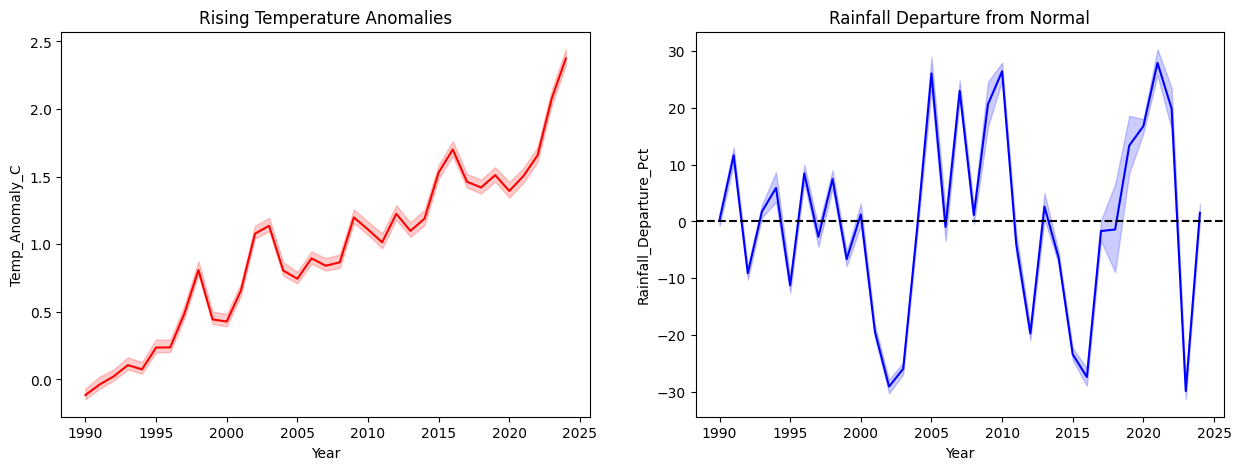

In [4]:
# Plot how temperature and rainfall have changed from 1990 to 2024
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(data=df, x=year_col, y=temp_col, ax=axes[0], color='red')
axes[0].set_title('Rising Temperature Anomalies')

sns.lineplot(data=df, x=year_col, y=rain_col, ax=axes[1], color='blue')
axes[1].axhline(0, color='black', linestyle='--') # The "Normal" baseline
axes[1].set_title('Rainfall Departure from Normal')
plt.show()

### Step 3: Climate vs. Agriculture Correlation

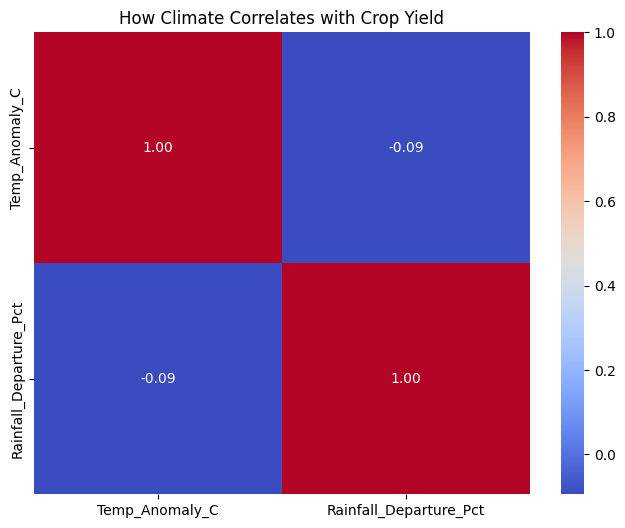

In [5]:
# See how climate variables statistically relate to crop yield
impact_vars = [temp_col, rain_col, 'annual_rainfall_mm', 'yield_kg_per_ha']
existing_vars = [var for var in impact_vars if var in df.columns]

plt.figure(figsize=(8, 6))
sns.heatmap(df[existing_vars].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('How Climate Correlates with Crop Yield')
plt.show()

### Step 4: Vulnerability Clustering (K-Means)

In [6]:
# Group districts into Risk Tiers (Low, Medium, High) based on dry days & rainfall
cluster_vars = ['annual_rainfall_mm', 'max_consecutive_dry_days_cdd']
cluster_vars = [v for v in cluster_vars if v in df.columns]

if len(cluster_vars) == 2:
    # Train the K-Means model to find 3 risk clusters
    kmeans = KMeans(n_clusters=3, random_state=42)
    df['Risk_Cluster'] = kmeans.fit_predict(df[cluster_vars])

    # Plot the distinct vulnerability zones
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x='annual_rainfall_mm', y='max_consecutive_dry_days_cdd', hue='Risk_Cluster', palette='Set1')
    plt.title('District Vulnerability Zones (AI Clustering)')
    plt.show()

### Step 5: Predicting Crop Yield (Machine Learning)

In [7]:
# Use a Random Forest to predict agricultural yield based on climate factors
ml_features = ['annual_rainfall_mm', temp_col, 'max_consecutive_dry_days_cdd']
target = 'yield_kg_per_ha'

ml_features = [f for f in ml_features if f in df.columns]

if len(ml_features) > 0 and target in df.columns:
    X = df[ml_features]
    y = df[target]

    # Split data to test the model on unseen data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Train the model
    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Show which climate factors have the biggest impact on yield
    importances = pd.DataFrame({'Feature': ml_features, 'Impact': model.feature_importances_})
    importances = importances.sort_values(by='Impact', ascending=False)

    plt.figure(figsize=(8, 4))
    sns.barplot(data=importances, x='Impact', y='Feature', palette='viridis')
    plt.title('Most Critical Climate Drivers of Crop Yield')
    plt.show()

### Step 6: Interactive Dashboard Explorer

In [8]:
import ipywidgets as widgets
from IPython.display import display, clear_output

sns.set_theme(style="whitegrid", palette="deep")

district_col = 'district_name_harmonized' if 'district_name_harmonized' in df.columns else 'District'
year_col = 'calendar_year' if 'calendar_year' in df.columns else 'Year'
temp_anomaly_col = 'temperature_anomaly_c' if 'temperature_anomaly_c' in df.columns else 'Temp_Anomaly_C'
rainfall_dept_col = 'rainfall_departure_pct' if 'rainfall_departure_pct' in df.columns else 'Rainfall_Departure_Pct'

districts = sorted(df[district_col].dropna().unique().tolist())
districts.insert(0, 'All Districts (State Average)')

district_dropdown = widgets.Dropdown(
    options=districts,
    value='All Districts (State Average)',
    description='Select District:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='400px')
)

def update_dashboard(selected_district):
    if selected_district == 'All Districts (State Average)':
        data = df.groupby(year_col).mean(numeric_only=True).reset_index()
        title_suffix = "Across Karnataka"
    else:
        data = df[df[district_col] == selected_district].sort_values(year_col)
        title_suffix = f"in {selected_district}"

    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    fig.suptitle(f'Climate & Socio-Economic Impact Dashboard: {title_suffix}', fontsize=18, weight='bold', y=1.02)

    # Top-Left: Temperature Anomaly Trend
    sns.lineplot(ax=axes[0, 0], data=data, x=year_col, y=temp_anomaly_col, color='crimson', linewidth=2.5, marker='o')
    axes[0, 0].set_title('Temperature Anomaly Over Time (°C)', fontsize=14)
    axes[0, 0].set_ylabel('Anomaly (°C)')
    axes[0, 0].set_xlabel('Year')

    # Top-Right: Rainfall Departure Trend
    sns.lineplot(ax=axes[0, 1], data=data, x=year_col, y=rainfall_dept_col, color='royalblue', linewidth=2.5, marker='s')
    axes[0, 1].axhline(0, color='black', linestyle='--', linewidth=1.5)
    axes[0, 1].set_title('Rainfall Departure from Normal (%)', fontsize=14)
    axes[0, 1].set_ylabel('Departure (%)')
    axes[0, 1].set_xlabel('Year')

    # Bottom-Left: Seasonal Rainfall vs Crop Yield
    if 'seasonal_rainfall_mm' in data.columns and 'yield_kg_per_ha' in data.columns:
        sns.scatterplot(ax=axes[1, 0], data=data, x='seasonal_rainfall_mm', y='yield_kg_per_ha',
                        hue=year_col, palette='viridis', size='production_tonnes', sizes=(50, 500))
        axes[1, 0].set_title('Seasonal Rainfall vs. Crop Yield', fontsize=14)
        axes[1, 0].set_xlabel('Seasonal Rainfall (mm)')
        axes[1, 0].set_ylabel('Crop Yield (kg/ha)')
    else:
        axes[1, 0].text(0.5, 0.5, 'Metrics for Scatterplot missing.',
                        horizontalalignment='center', verticalalignment='center', fontsize=12, style='italic')
        axes[1, 0].axis('off')

    # Bottom-Right: Key Climate & Risk Indicators (Bar Chart)
    if selected_district != 'All Districts (State Average)' and len(data) > 0:
        latest_data = data.iloc[-1]
        metrics = ['max_consecutive_dry_days_cdd', 'rainy_days_count', 'tmean_c']
        valid_metrics = [m for m in metrics if m in latest_data.index]
        values = [latest_data[m] for m in valid_metrics]
        labels = [m.replace('_', ' ').title() for m in valid_metrics]

        if len(valid_metrics) > 0:
            sns.barplot(ax=axes[1, 1], x=values, y=labels, palette='autumn')
            axes[1, 1].set_title(f'Latest Risk Metrics ({latest_data[year_col]})', fontsize=14)
            axes[1, 1].set_xlabel('Score / Quantity')
        else:
            axes[1, 1].axis('off')
    else:
        axes[1, 1].text(0.5, 0.5, 'Select a specific district to view localized risk metrics.',
                        horizontalalignment='center', verticalalignment='center', fontsize=12, style='italic')
        axes[1, 1].axis('off')

    plt.tight_layout()
    plt.show()

interactive_plot = widgets.interactive_output(update_dashboard, {'selected_district': district_dropdown})

display(widgets.VBox([
    widgets.HTML("<h3>📊 NIErnaya Phase 2: District-Level Climate Impact Explorer</h3>"),
    district_dropdown,
    interactive_plot
]))